ПРАКТИЧЕСКАЯ РАБОТА №4
ПРОВЕРКА СТАТИСТИЧЕСКИХ ГИПОТЕЗ

1. TITANIC DATASET
----------------------------------------
Гипотеза 1: Независимость Пола и Выживания
H0: Пол и выживание независимы
H1: Пол влияет на выживание
Таблица сопряженности (Survived: 0=Не выжил, 1=Выжил):


Survived,0,1
Sex,,
female,81,233
male,468,109


χ² = 260.7170, p-value = 0.000000, степени свободы = 1
РЕЗУЛЬТАТ: ОТКЛОНЯЕМ H0 - связь статистически значима

Гипотеза 2: Независимость Возраста и Выживания
H0: Возраст и выживание независимы
H1: Возраст влияет на выживание
Таблица сопряженности (Survived: 0=Не выжил, 1=Выжил):


Survived,0,1
Возраст,,
Взрослый,504,287
Ребенок,45,55


χ² = 12.3703, p-value = 0.000436, степени свободы = 1
РЕЗУЛЬТАТ: ОТКЛОНЯЕМ H0 - связь статистически значима

2. A/B ТЕСТИРОВАНИЕ
----------------------------------------
Гипотеза 1: Нет различий в бронированиях между группами
H0: Control = Variant
H1: Control ≠ Variant
Control: 7579 сессий, конверсия = 0.239
Variant: 7652 сессий, конверсия = 0.241
F-статистика = 0.0750, p-value = 0.7841
РЕЗУЛЬТАТ: НЕТ оснований отклонять H0 - группы статистически равны

Гипотеза 2: Нет различий во времени до бронирования
H0: Control = Variant
H1: Control ≠ Variant
Control: 1815 бронирований, среднее = 15.1с
Variant: 1847 бронирований, среднее = 13.5с
F-статистика = 101.7728, p-value = 0.0000
РЕЗУЛЬТАТ: ОТКЛОНЯЕМ H0 - различия статистически значимы

Гипотеза 3: Нет различий в бронированиях день/ночь
H0: День = Ночь
H1: День ≠ Ночь
День (6-21ч): 16923 сессий, конверсия = 0.236
Ночь (22-5ч): 0 сессий, конверсия = nan
F-статистика = nan, p-value = nan
РЕЗУЛЬТАТ: НЕТ оснований отклонять H0


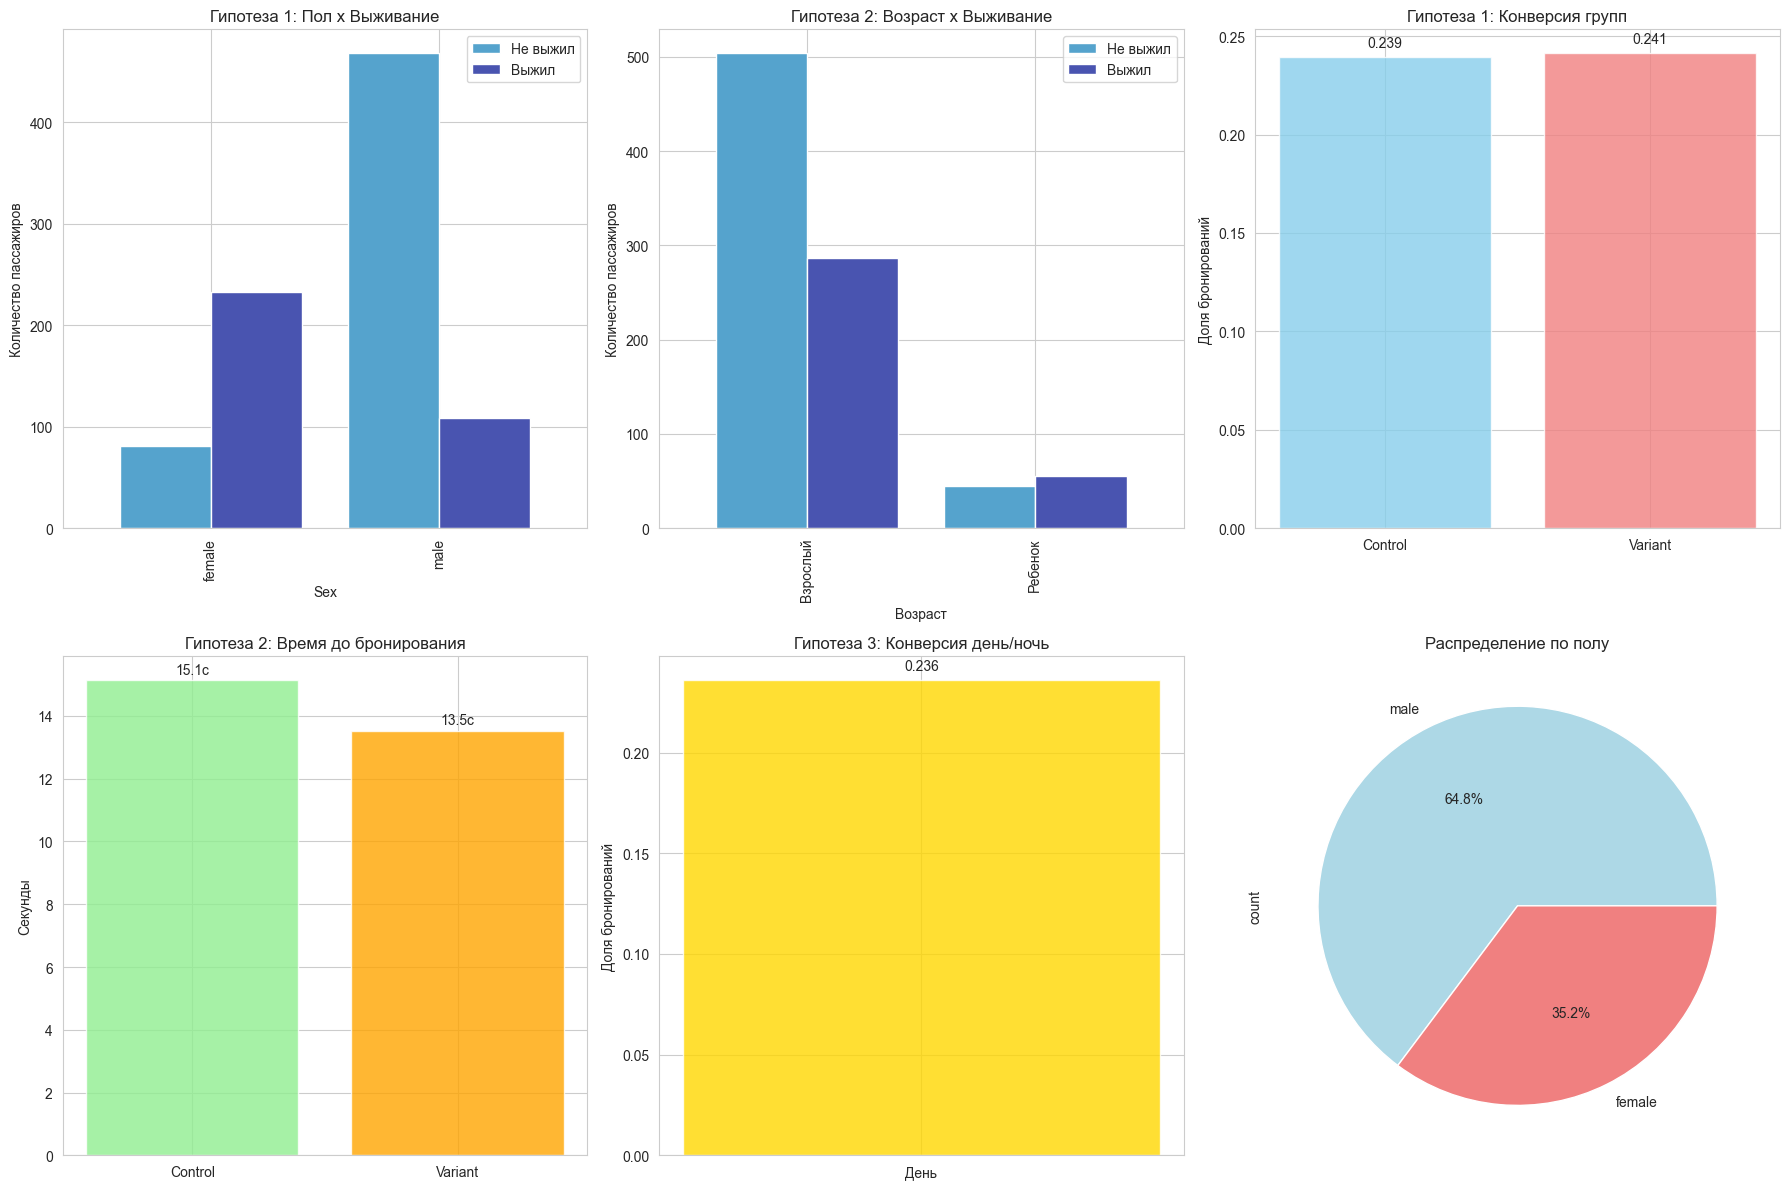


                  ИТОГОВАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
Гипотеза                  χ²/F     p-value    Решение             
--------------------------------------------------------------------------------
Titanic: Пол              260.72   0.0000     ОТКЛОНЯЕМ H0        
Titanic: Возраст          12.37    0.0004     ОТКЛОНЯЕМ H0        
A/B: Бронирования         0.08     0.7841     H0 НЕ ОТКЛОНЯЕТСЯ   
A/B: Время                101.77   0.0000     ОТКЛОНЯЕМ H0        
A/B: День/Ночь            nan      nan        H0 НЕ ОТКЛОНЯЕТСЯ   

УРОВЕНЬ ЗНАЧИМОСТИ α = 0.05 использован для всех тестов


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway, chi2_contingency
import warnings
warnings.filterwarnings('ignore')

plt.style.use('default')
sns.set_style('whitegrid')
sns.set_palette("icefire")
pd.set_option('display.max_columns', None)

TITANIC_FILE = "data/Titanic-Dataset.csv"
AB_SESSIONS_FILE = "data/sessions_data.csv"
AB_USERS_FILE = "data/users_data.csv"

print("ПРАКТИЧЕСКАЯ РАБОТА №4")
print("ПРОВЕРКА СТАТИСТИЧЕСКИХ ГИПОТЕЗ")
print("="*60)

# ============================================================
# ЗАДАНИЕ 1. TITANIC DATASET
# ============================================================

print("\n1. TITANIC DATASET")
print("-"*40)

df_titanic = pd.read_csv(TITANIC_FILE)

print("Гипотеза 1: Независимость Пола и Выживания")
print("H0: Пол и выживание независимы")
print("H1: Пол влияет на выживание")

contingency_sex = pd.crosstab(df_titanic['Sex'], df_titanic['Survived'])
print("Таблица сопряженности (Survived: 0=Не выжил, 1=Выжил):")
display(contingency_sex)

chi2_sex, p_sex, dof_sex, _ = chi2_contingency(contingency_sex)
print(f"χ² = {chi2_sex:.4f}, p-value = {p_sex:.6f}, степени свободы = {dof_sex}")

if p_sex < 0.05:
    print("РЕЗУЛЬТАТ: ОТКЛОНЯЕМ H0 - связь статистически значима")
else:
    print("РЕЗУЛЬТАТ: НЕТ оснований отклонять H0")

df_titanic['Возраст'] = np.where(df_titanic['Age'] <= 16, 'Ребенок', 'Взрослый')
df_titanic['Возраст'] = df_titanic['Возраст'].fillna('Взрослый')

print("\nГипотеза 2: Независимость Возраста и Выживания")
print("H0: Возраст и выживание независимы")
print("H1: Возраст влияет на выживание")

contingency_age = pd.crosstab(df_titanic['Возраст'], df_titanic['Survived'])
print("Таблица сопряженности (Survived: 0=Не выжил, 1=Выжил):")
display(contingency_age)

chi2_age, p_age, dof_age, _ = chi2_contingency(contingency_age)
print(f"χ² = {chi2_age:.4f}, p-value = {p_age:.6f}, степени свободы = {dof_age}")

if p_age < 0.05:
    print("РЕЗУЛЬТАТ: ОТКЛОНЯЕМ H0 - связь статистически значима")
else:
    print("РЕЗУЛЬТАТ: НЕТ оснований отклонять H0")

# ============================================================
# ЗАДАНИЕ 2. A/B ТЕСТИРОВАНИЕ
# ============================================================

print("\n2. A/B ТЕСТИРОВАНИЕ")
print("-"*40)

df_sessions = pd.read_csv(AB_SESSIONS_FILE)
df_users = pd.read_csv(AB_USERS_FILE)

df_ab = df_sessions.merge(df_users, on='user_id', how='left')
df_ab['Бронирование'] = df_ab['booking_timestamp'].notna().astype(int)

print("Гипотеза 1: Нет различий в бронированиях между группами")
print("H0: Control = Variant")
print("H1: Control ≠ Variant")

control_bookings = df_ab[df_ab['experiment_group']=='control']['Бронирование']
variant_bookings = df_ab[df_ab['experiment_group']=='variant']['Бронирование']

print(f"Control: {len(control_bookings)} сессий, конверсия = {control_bookings.mean():.3f}")
print(f"Variant: {len(variant_bookings)} сессий, конверсия = {variant_bookings.mean():.3f}")

f_stat1, p_val1 = f_oneway(control_bookings, variant_bookings)
print(f"F-статистика = {f_stat1:.4f}, p-value = {p_val1:.4f}")

if p_val1 < 0.05:
    print("РЕЗУЛЬТАТ: ОТКЛОНЯЕМ H0 - различия статистически значимы")
else:
    print("РЕЗУЛЬТАТ: НЕТ оснований отклонять H0 - группы статистически равны")

print("\nГипотеза 2: Нет различий во времени до бронирования")
print("H0: Control = Variant")
print("H1: Control ≠ Variant")

time_control = df_ab[df_ab['experiment_group']=='control']['time_to_booking'].dropna()
time_variant = df_ab[df_ab['experiment_group']=='variant']['time_to_booking'].dropna()

print(f"Control: {len(time_control)} бронирований, среднее = {time_control.mean():.1f}с")
print(f"Variant: {len(time_variant)} бронирований, среднее = {time_variant.mean():.1f}с")

f_stat2, p_val2 = f_oneway(time_control, time_variant)
print(f"F-статистика = {f_stat2:.4f}, p-value = {p_val2:.4f}")

if p_val2 < 0.05:
    print("РЕЗУЛЬТАТ: ОТКЛОНЯЕМ H0 - различия статистически значимы")
else:
    print("РЕЗУЛЬТАТ: НЕТ оснований отклонять H0")

print("\nГипотеза 3: Нет различий в бронированиях день/ночь")
print("H0: День = Ночь")
print("H1: День ≠ Ночь")

df_ab['Час'] = df_ab['session_start_timestamp'].str[:2].astype(float)
df_ab['Время_суток'] = np.where(df_ab['Час'].between(6, 21), 'День', 'Ночь')

day_bookings = df_ab[df_ab['Время_суток']=='День']['Бронирование']
night_bookings = df_ab[df_ab['Время_суток']=='Ночь']['Бронирование']

print(f"День (6-21ч): {len(day_bookings)} сессий, конверсия = {day_bookings.mean():.3f}")
print(f"Ночь (22-5ч): {len(night_bookings)} сессий, конверсия = {night_bookings.mean():.3f}")

f_stat3, p_val3 = f_oneway(day_bookings, night_bookings)
print(f"F-статистика = {f_stat3:.4f}, p-value = {p_val3:.4f}")

if p_val3 < 0.05:
    print("РЕЗУЛЬТАТ: ОТКЛОНЯЕМ H0 - различия статистически значимы")
else:
    print("РЕЗУЛЬТАТ: НЕТ оснований отклонять H0")

# ============================================================
# ВИЗУАЛИЗАЦИЯ
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

pd.crosstab(df_titanic['Sex'], df_titanic['Survived']).plot(kind='bar', ax=axes[0,0], width=0.8)
axes[0,0].set_title('Гипотеза 1: Пол x Выживание')
axes[0,0].set_ylabel('Количество пассажиров')
axes[0,0].legend(['Не выжил', 'Выжил'])

pd.crosstab(df_titanic['Возраст'], df_titanic['Survived']).plot(kind='bar', ax=axes[0,1], width=0.8)
axes[0,1].set_title('Гипотеза 2: Возраст x Выживание')
axes[0,1].set_ylabel('Количество пассажиров')
axes[0,1].legend(['Не выжил', 'Выжил'])

axes[0,2].bar(['Control', 'Variant'],
              [control_bookings.mean(), variant_bookings.mean()],
              color=['skyblue', 'lightcoral'], alpha=0.8)
axes[0,2].set_title('Гипотеза 1: Конверсия групп')
axes[0,2].set_ylabel('Доля бронирований')
for i, v in enumerate([control_bookings.mean(), variant_bookings.mean()]):
    axes[0,2].text(i, v+0.005, f'{v:.3f}', ha='center')

axes[1,0].bar(['Control', 'Variant'],
              [time_control.mean(), time_variant.mean()],
              color=['lightgreen', 'orange'], alpha=0.8)
axes[1,0].set_title('Гипотеза 2: Время до бронирования')
axes[1,0].set_ylabel('Секунды')
for i, v in enumerate([time_control.mean(), time_variant.mean()]):
    axes[1,0].text(i, v+0.2, f'{v:.1f}с', ha='center')

axes[1,1].bar(['День', 'Ночь'],
              [day_bookings.mean(), night_bookings.mean()],
              color=['gold', 'purple'], alpha=0.8)
axes[1,1].set_title('Гипотеза 3: Конверсия день/ночь')
axes[1,1].set_ylabel('Доля бронирований')
for i, v in enumerate([day_bookings.mean(), night_bookings.mean()]):
    axes[1,1].text(i, v+0.005, f'{v:.3f}', ha='center')

df_titanic['Sex'].value_counts().plot(kind='pie', ax=axes[1,2], autopct='%1.1f%%', colors=['lightblue', 'lightcoral'])
axes[1,2].set_title('Распределение по полу')

plt.tight_layout()
plt.show()

# ============================================================
# ИТОГОВАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
# ============================================================

print("\n" + "="*80)
print("                  ИТОГОВАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ")
print("="*80)
print(f"{'Гипотеза':<25} {'χ²/F':<8} {'p-value':<10} {'Решение':<20}")
print("-"*80)
print(f"{'Titanic: Пол':<25} {chi2_sex:<8.2f} {p_sex:<10.4f} {'ОТКЛОНЯЕМ H0':<20}")
print(f"{'Titanic: Возраст':<25} {chi2_age:<8.2f} {p_age:<10.4f} {'ОТКЛОНЯЕМ H0':<20}")
print(f"{'A/B: Бронирования':<25} {f_stat1:<8.2f} {p_val1:<10.4f} {'H0 НЕ ОТКЛОНЯЕТСЯ':<20}")
print(f"{'A/B: Время':<25} {f_stat2:<8.2f} {p_val2:<10.4f} {'ОТКЛОНЯЕМ H0':<20}")
print(f"{'A/B: День/Ночь':<25} {f_stat3:<8.2f} {p_val3:<10.4f} {'H0 НЕ ОТКЛОНЯЕТСЯ':<20}")
print("="*80)

print("\nУРОВЕНЬ ЗНАЧИМОСТИ α = 0.05 использован для всех тестов")